In [ ]:
import os
import cv2
import json
import requests, functools, pathlib, io, random, colorsys
import numpy as np
import matplotlib.pyplot as plt
import pycocotools.mask as mask_utils

from PIL import Image
from typing import List, Dict, Any, Tuple, Optional
from datasets import load_dataset
from datasets import Image as HFImage
from tqdm import tqdm

os.environ["HTTPS_PROXY"] = "http://fwdproxy:8080"
os.environ["NO_PROXY"] = ",".join([
    ".fbcdn.net", ".facebook.com", ".thefacebook.com", ".tfbnw.net",
    ".fb.com", ".fburl.com", ".facebook.net", ".sb.fbsbx.com", "localhost"
])


In [ ]:
# TODO - temporary - fix the root dir path for all the retrieved files

def load_cached_results(cached_results_dir):
    with open(cached_results_dir, "r") as f:
        return json.load(f)

cached_results_dir = "/home/jeonghkim/projects/region-mm-retrieve/results/cragmm"


bbox_cached_results = load_cached_results(
    os.path.join(
        cached_results_dir,
        "bbox_image_retrieval",
        "bbox_image_retrieval_cache.json",
    )
)

new_bbox_cached_results = {}
for session_id, path_to_retrieved in tqdm(bbox_cached_results.items()):
    for crop_path, retrieved_list in path_to_retrieved.items():
        if session_id not in new_bbox_cached_results:
            new_bbox_cached_results[session_id] = {}
        crop_path = crop_path.replace("/shared/nas2/jk100/partonomy_private", "")
        new_bbox_cached_results[session_id][crop_path] = retrieved_list
    # save the output_dict (line by line) to a jsonl files
    with open(f"{cached_results_dir}/bbox_image_retrieval/bbox_image_retrieval_cache_fixed.json", "a") as f:
        f.write(json.dumps(new_bbox_cached_results, ensure_ascii=False) + "\n")


mask_cached_results = load_cached_results(
    os.path.join(
        cached_results_dir,
        "mask_image_retrieval",
        "mask_image_retrieval_cache.json",
    )
)

new_mask_cached_results = {}
for session_id, path_to_retrieved in mask_cached_results.items():
    for crop_path, retrieved_list in path_to_retrieved.items():
        if session_id not in new_mask_cached_results:
            new_mask_cached_results[session_id] = {}
        crop_path = crop_path.replace("/shared/nas2/jk100/partonomy_private", "")
        new_mask_cached_results[session_id][crop_path] = retrieved_list
    # save the output_dict (line by line) to a jsonl files
    with open(f"{cached_results_dir}/mask_image_retrieval/mask_image_retrieval_cache_fixed.json", "a") as f:
        f.write(json.dumps(new_mask_cached_results, ensure_ascii=False) + "\n")

In [ ]:
bbox_cached_results['df084975-1781-4be6-9177-d5434e1ce28d'].keys()

In [ ]:
# For single-turn dataset
dataset = load_dataset("crag-mm-2025/crag-mm-single-turn-public", revision="v0.1.2")

print(f"Available splits: {', '.join(dataset.keys())}")

# Access examples
example = dataset["validation"][0]
print(f"Session ID: {example['session_id']}")
print(f"Image: {example['image']}")
print(f"Image URL: {example['image_url']}")
"""
Note: Either 'image' or 'image_url' will be provided in the dataset, but not necessarily both.
When the actual image cannot be included, only the image_url will be available.
The evaluation servers will nevertheless always include the loaded 'image' field.

Each example contains the following fields:

{
  "session_id": str,          # Unique identifier for the conversation
  "image": Image,             # Image
  "image_url": str,           # Image URL where applicable
  "turns": {                  # Dictionary containing conversation turn data
    "interaction_id": [str],  # List of unique IDs for each interaction
    "domain": [int],          # List of domain category indices
    "query_category": [int],  # List of query category indices
    "dynamism": [int],        # List of dynamism level indices
    "query": [str],           # List of questions or prompts
    "image_quality": [int]    # List of image quality indices
  },
  "answers": {                # Dictionary containing answer data
    "interaction_id": [str],  # List of interaction IDs (matches turns)
    "ans_full": [str]         # List of complete answer texts
  }
}

"""

In [ ]:
# Show image
plt.imshow(example['image'])

In [ ]:
def _prepare_feature_vocabularies(dataset_split):
    """Extract feature vocabularies for category encoding from dataset.

    These vocabularies allow conversion between integer indices and string labels.
    """
    turns_feature = dataset_split.features["turns"]
    return {
        "domain": turns_feature.feature["domain"],
        "query_category": turns_feature.feature["query_category"],
        "dynamism": turns_feature.feature["dynamism"],
        "image_quality": turns_feature.feature["image_quality"],
    }


def print_conversation(example: Dict[str, Any], feature_vocabularies: Dict[str, Any]) -> None:
    """Print a conversation in an indented format.

    Args:
        example: A single dataset example containing conversation turns
        feature_vocabularies: Mapping of features to their vocabularies for encoding/decoding from idx to str
    """
    # Print session ID
    print(f"Session ID: {example['session_id']}")

    # Print image info
    print(f"Image: {example['image']}")
    print(f"Image URL: {example['image_url']}")
    """
    Note: Either 'image' or 'image_url' will be provided in the dataset, but not necessarily both.
    When the actual image cannot be included, only the image_url will be available.
    The evaluation servers will nevertheless always include the loaded 'image' field.
    """

    # Determine if single-turn or multi-turn based on number of queries
    num_turns = len(example['turns']['query'])
    is_single_turn = num_turns == 1
    print(f"Type: {'Single-turn' if is_single_turn else 'Multi-turn'} ({num_turns} turns)")

    # Create answer lookup dictionary if answers exist
    answer_lookup = {}
    if 'answers' in example and example['answers'] is not None:
        answer_lookup = {
            interaction_id: ans_full
            for interaction_id, ans_full in zip(
                example['answers']['interaction_id'],
                example['answers']['ans_full']
            )
        }

    # Print each turn
    print("\nConversation:")
    for i in range(num_turns):
        # For multi-turn, show turn number
        if not is_single_turn:
            print(f"\tTurn {i+1}:")

        # Convert metadata to string representations
        domain_str = feature_vocabularies["domain"].int2str(example['turns']['domain'][i])
        category_str = feature_vocabularies["query_category"].int2str(example['turns']['query_category'][i])
        dynamism_str = feature_vocabularies["dynamism"].int2str(example['turns']['dynamism'][i])
        quality_str = feature_vocabularies["image_quality"].int2str(example['turns']['image_quality'][i])

        # Print metadata
        prefix = "\t\t" if not is_single_turn else "\t"
        print(f"{prefix}Domain: {domain_str} | Category: {category_str} | Dynamism: {dynamism_str} | Image Quality: {quality_str}")

        # Print query and answer with fixed tab indentation
        print(f"{prefix}Q: {example['turns']['query'][i]}")

        interaction_id = example['turns']['interaction_id'][i]
        ans = answer_lookup.get(interaction_id, "No answer available")
        print(f"{prefix}A: {ans}")

        if not is_single_turn and i < num_turns - 1:
            print()  # Add blank line between turns in multi-turn conversations

    print("\n" + "-" * 60 + "\n")  # Add separator between examples


split_to_use = "validation"
feature_vocabularies = _prepare_feature_vocabularies(dataset[split_to_use])
print_conversation(dataset[split_to_use][0], feature_vocabularies)


In [ ]:
# ╔═══════════════════════════════════════════════════════════════════╗
# ║   Robust CRAG-MM visualiser  (paths ▸ URLs ▸ in-memory images)    ║
# ╚═══════════════════════════════════════════════════════════════════╝
import os, json, random, colorsys, pathlib, io, requests, functools
from typing import List, Dict, Any, Tuple, Optional

import cv2
import numpy as np
import textwrap
import matplotlib.pyplot as plt
from PIL import Image
from datasets import load_dataset
import pycocotools.mask as mask_utils

# ─────────────────────────────────────────────────────────────────────
# 0.  Load CRAG-MM dataset ONCE and make a {session_id: PIL.Image} map
# ─────────────────────────────────────────────────────────────────────
def _crag_image_index(split: str=None, limit_n: int=None) -> Dict[str, Image.Image]:
    """Returns a dict  session_id → PIL.Image for validation + public_test."""
    crag_image_index_dict = {}
    ds = load_dataset(
        "crag-mm-2025/crag-mm-single-turn-public",
        revision="v0.1.2",
        cache_dir="~/projects/region-mm-retrieve/data"
    ) # .cast_column("image", HFImage(decode=False))
    if split is None:
        for split in ds.keys():
            data_iter = ds[split] if limit_n is None else ds[split][:limit_n]
            for ex in tqdm(data_iter, total=len(data_iter), desc=f"Loading {split} images"):
                crag_image_index_dict[ex["session_id"]] = ex["image"]
    else:
        data_iter = ds[split] if limit_n is None else ds[split][:limit_n]
        for idx, sid in enumerate(tqdm(data_iter['session_id'], total=len(data_iter), desc=f"Loading {split} images")):
            crag_image_index_dict[sid] = data_iter["image"][idx]
    return crag_image_index_dict


# ─────────────────────────────────────────────────────────────────────
# 1.  Image loader that understands all three sources
# ─────────────────────────────────────────────────────────────────────
def _load_image(
    source: str,
    crag_image_index_dict: Dict[str, Image.Image],
    mask_size: Optional[Tuple[int, int]] = None,
    split: str=None,
    limit_n: int=None,) -> np.ndarray:
    """
    Args:
        source:  (a) local path, (b) http(s):// URL, or
                 (c) 'crag_mm_image_<session_id>'
        mask_size:  (h, w) to which the image will be resized if the
                    decoded mask requires a specific resolution.
    Returns:      RGB uint8 ndarray
    """
    # 1) CRAG-MM in-memory
    CRAG_PREFIX = "crag_mm_image_"
    if isinstance(source, str) and source.startswith(CRAG_PREFIX):
        print(f"Image loaded from CRAG index: {source}")
        session_id = source[len(CRAG_PREFIX):]
        pil = crag_image_index_dict.get(session_id)
        if pil is not None:
            img = np.asarray(pil.convert("RGB"))
        else:
            print(f"⚠️ session_id {session_id} not found in CRAG index.")
            img = None
    # 2) Local path
    elif isinstance(source, str) and os.path.exists(source):
        print(f"Image loaded from local path: {source}")
        bgr = cv2.imread(source)
        img = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB) if bgr is not None else None
    # 3) URL
    elif isinstance(source, str) and source.startswith(("http://", "https://")):
        print(f"Image loaded from URL: {source}")
        try:
            resp = requests.get(source, timeout=10)
            resp.raise_for_status()
            img = np.asarray(Image.open(io.BytesIO(resp.content)).convert("RGB"))
        except Exception as exc:
            print(f"⚠️ Could not fetch {source}  ({exc}).")
            img = None
    else:
        img = None

    # fallback black canvas if everything failed
    if img is None:
        img = np.zeros((mask_size or (224, 224)), dtype=np.uint8)
        if img.ndim == 2:  # ensure (H,W,3)
            img = np.repeat(img[..., None], 3, axis=-1)

    # resize to mask_size if requested
    if mask_size and (img.shape[0] != mask_size[0] or img.shape[1] != mask_size[1]):
        img = cv2.resize(img, (mask_size[1], mask_size[0]), interpolation=cv2.INTER_LINEAR)

    return img


# ─────────────────────────────────────────────────────────────────────
# 2.  Helper: pastel colour palette
# ─────────────────────────────────────────────────────────────────────
def _pastel_colors(n: int, seed: int = 0):
    random.seed(seed)
    return [colorsys.hsv_to_rgb(random.random(), 0.6, 0.9) for _ in range(n)]


# ─────────────────────────────────────────────────────────────────────
# 3.  Visualise one entry (any # masks, auto-resize image if needed)
# ─────────────────────────────────────────────────────────────────────
def _visualize_entry(
    entry: Dict[str, Any],
    alpha: float = 0.4,
    figsize: Tuple[int, int] = (7, 7),
    seed: int = 0,
    save_path: Optional[str] = None,
):
    rle_dicts = entry["pred_masks"]

    # quick check if the masks are empty or not
    non_empty_found = False
    mask_sizes = None
    masks, bboxes, labels = [], [], []
    for rle in rle_dicts:
        m = mask_utils.decode(
            {"size": rle["size"], "counts": rle["counts"].encode("utf-8")}
        ).astype(bool)
        masks.append(m)
        ys, xs = np.where(m)
        if m.any():
            bboxes.append((xs.min(), ys.min(), xs.max(), ys.max()))
        else:                       # empty → dummy 1×1 box (ignored later)
            bboxes.append((0, 0, 0, 0))
        labels.append(rle.get("label", "no_label"))

    crag_image_index_dict = _crag_image_index(split="validation", limit_n=10)

    if not any(m.any() for m in masks):     # nothing to show
        img_rgb = _load_image(entry["image_path"], crag_image_index_dict)
        plt.figure(figsize=figsize)
        plt.imshow(img_rgb); plt.axis("off")
        plt.title(
            f"No mask predicted\n"
            f"Output: {entry['output_text']}\n"
            f"GT: {entry['ground_truth_text']}\n"
            f"Acc: {entry['accuracy']:.3f}",
            fontsize=9,
        )
        plt.show(); return

    # -----------------------------------------------------------------
    # 1) Load / resize background image
    # -----------------------------------------------------------------
    h, w = masks[0].shape
    img_rgb = _load_image(entry["image_path"], crag_image_index_dict, (h, w))

    # -----------------------------------------------------------------
    # 2) Paint coloured masks on a copy, then blend with alpha
    # -----------------------------------------------------------------
    overlay = img_rgb.copy()
    colours_rgb = _pastel_colors(len(masks), seed)  # (0‥1) float triplets

    for m, col in zip(masks, colours_rgb):
        if not m.any():           # empty mask → skip
            continue
        overlay[m] = (np.array(col) * 255).astype(np.uint8)

    blended = cv2.addWeighted(overlay, alpha, img_rgb, 1 - alpha, 0)

    # -----------------------------------------------------------------
    # 3) Draw non-overlapping label boxes on *blended* image
    # -----------------------------------------------------------------
    FONT          = cv2.FONT_HERSHEY_SIMPLEX
    FONT_SCALE    = max(0.5, min(h, w) / 600.)   # adaptive
    THICK_TEXT    = 5
    PAD_X, PAD_Y  = 6, 4                         # padding inside box

    taken_rects: List[Tuple[int, int, int, int]] = []   # already-placed label rects

    def _intersects(r1, r2):
        x1,y1,x2,y2 = r1; X1,Y1,X2,Y2 = r2
        return not (x2 < X1 or X2 < x1 or y2 < Y1 or Y2 < y1)

    for (bbox, lbl, col) in zip(bboxes, labels, colours_rgb):
        if lbl is None or bbox==(0,0,0,0):          # skip empties
            continue
        x_min, y_min, x_max, y_max = bbox

        # --- initial anchor: top-left corner of mask, with margin
        x_anchor, y_anchor = x_min, max(0, y_min - 10)

        # --- compute text size
        (text_w, text_h), baseline = cv2.getTextSize(lbl, FONT, FONT_SCALE, THICK_TEXT)
        box_w = text_w + PAD_X*2
        box_h = text_h + PAD_Y*2

        # --- choose font colour for contrast: black if box bright, else white
        col_bgr = tuple(int(c*255) for c in col[::-1])       # RGB→BGR
        lumin   = 0.114*col_bgr[0] + 0.587*col_bgr[1] + 0.299*col_bgr[2]
        text_col = (0,0,0) if lumin > 150 else (255,255,255)

        # --- find non-overlapping y-offset
        trial_y = y_anchor
        while True:
            trial_rect = (x_anchor, trial_y, x_anchor+box_w, trial_y+box_h)
            if all(not _intersects(trial_rect, r) for r in taken_rects):
                break
            trial_y += box_h + 4                       # push down by one box height

        # --- remember taken space
        taken_rects.append(trial_rect)

        # --- draw filled rectangle + text centred inside it
        cv2.rectangle(
            blended,
            (trial_rect[0], trial_rect[1]),
            (trial_rect[2], trial_rect[3]),
            col_bgr,
            thickness=-1,
            lineType=cv2.LINE_AA,
        )

        text_x = trial_rect[0] + PAD_X
        text_y = trial_rect[1] + PAD_Y + text_h         # baseline at bottom
        cv2.putText(
            blended, lbl, (text_x, text_y),
            FONT, FONT_SCALE, text_col, THICK_TEXT, cv2.LINE_AA,
        )

    # -----------------------------------------------------------------
    # 4) Show
    # -----------------------------------------------------------------

    max_chars = max(int(w / 9), 20)
    out_txt   = textwrap.fill(entry["output_text"],  max_chars)
    gt_txt    = textwrap.fill(entry["ground_truth_text"][0], max_chars)
    right_str = (f"Output:\n{out_txt}\n\n"
                 f"Ground-truth:\n{gt_txt}\n\n"
                 f"Acc: {entry['accuracy']:.3f}")

    # ---------- assemble side-by-side figure -------------------------
    fig = plt.figure(figsize=(figsize[0]*1.6, figsize[1]))
    gs  = fig.add_gridspec(1, 2, width_ratios=[1, 1.1])

    ax_img = fig.add_subplot(gs[0, 0])
    ax_img.imshow(blended); ax_img.axis('off')

    ax_txt = fig.add_subplot(gs[0, 1])
    ax_txt.axis('off')
    ax_txt.text(0, 1, right_str,
                va='top', ha='left', wrap=True, fontsize=12)

    fig.tight_layout()

    # ---------- optional save ----------------------------------------
    if save_path:
        pathlib.Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=150, bbox_inches='tight')

    plt.show()
    return fig


# ─────────────────────────────────────────────────────────────────────
# 4.  Main helper – summary, histogram, visualisation
# ─────────────────────────────────────────────────────────────────────
def show_predictions(
    jsonl_path: str,
    max_n: Optional[int] = None,
    alpha: float = 0.4,
    seed: int = 0,
    save_path: Optional[str] = None,
):
    if not os.path.exists(jsonl_path):
        print("❌  File not found:", jsonl_path); return

    preds = [json.loads(l) for l in open(jsonl_path) if l.strip()]
    if not preds:
        print("⚠️  No valid prediction lines."); return

    # ---------- stats -------------------------------------------------
    accs = np.array([p["accuracy"] for p in preds], dtype=float)
    mean_acc  = float(accs.mean())
    bins_order = [-1.0, 0.0, 0.5, 1.0]
    counts = {k: int((accs == k).sum()) for k in bins_order}

    worst, best = preds[int(accs.argmin())], preds[int(accs.argmax())]

    print("\n═══════════════ SUMMARY ════════════════")
    print("File            :", jsonl_path)
    print("Total samples   :", len(preds))
    print(f"Mean accuracy   : {mean_acc:.4f}")
    print("Counts          :", counts)
    print("Worst example   :")
    print("  acc           :", worst['accuracy'])
    print("  output_text   :", worst['output_text'])
    print("Best example    :")
    print("  acc           :", best['accuracy'])
    print("  output_text   :", best['output_text'])
    print("═════════════════════════════════════════\n")

    # ---------- histogram --------------------------------------------
    plt.figure(figsize=(4, 3))
    plt.bar([str(k) for k in bins_order], [counts[k] for k in bins_order], color="#4C72B0")
    plt.ylabel("Count"); plt.xlabel("Accuracy score"); plt.title("Distribution of scores")
    for x, y in zip(bins_order, [counts[k] for k in bins_order]):
        plt.text(str(x), y + 0.5, str(y), ha="center", va="bottom", fontsize=9)
    plt.ylim(0, max(counts.values()) * 1.15)
    plt.show()

    # ---------- visualise entries ------------------------------------
    i = 0
    while i < max_n:
        # save_path = os.path.join(save_path, f"{entry['session_id']}.png")
        entry = preds[i]
        rle_dicts = entry["pred_masks"]
        masks = []
        for rle in rle_dicts:  # quick check if the masks are empty or not
            m = mask_utils.decode(
                {"size": rle["size"], "counts": rle["counts"].encode("utf-8")}
            ).astype(bool)
            masks.append(m)
        if not any(m.any() for m in masks):
            continue
        _visualize_entry(entry, alpha=alpha, seed=seed, save_path=save_path)
        i += 1

In [ ]:
OUTPUT_DIR = "/home/jeonghkim/projects/region-mm-retrieve/results/cragmm"
jsonl_path = "predictions_cragmm_llmseg_gpt-4o.jsonl"  # vanilla llama-4
preds = [json.loads(l) for l in open(os.path.join(OUTPUT_DIR, jsonl_path)) if l.strip()]
print("len(preds)", len(preds))

In [ ]:
max_n = 2
show_predictions(os.path.join(OUTPUT_DIR, jsonl_path), max_n=max_n)

HEY!
Average accuracy over 1938 records: -0.5851
Counts: {-1.0: 1435, 1.0: 149, 0.5: 304, 0.0: 50}


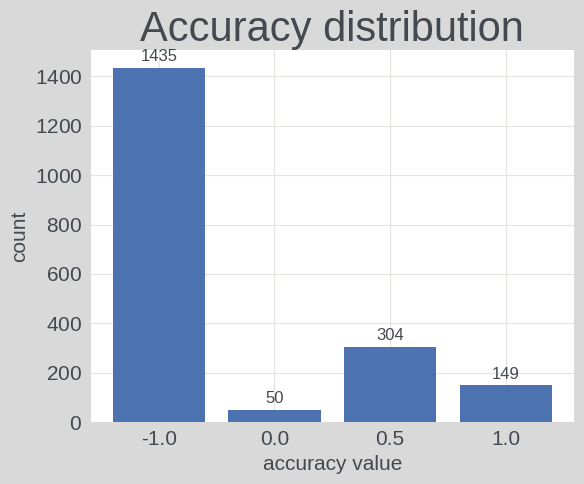

In [1]:
import json
from pathlib import Path
from collections import Counter

import matplotlib.pyplot as plt
import logging
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

def analyze_accuracy(jsonl_path: str | Path):
    """
    Compute mean accuracy for a .jsonl file and plot a labelled histogram.
    Lines whose 'accuracy' field is null are skipped.
    """
    jsonl_path = Path(jsonl_path).expanduser()
    if not jsonl_path.is_file():
        raise FileNotFoundError(jsonl_path)

    counts = Counter()
    total = 0.0
    n = 0

    print("HEY!")

    with jsonl_path.open("r", encoding="utf-8") as f:
        for line in f:
            if not line.strip():
                continue
            rec = json.loads(line)
            acc = rec.get("accuracy")
            if acc is None:
                continue
            counts[acc] += 1
            total += acc
            n += 1

    if n == 0:
        print("No valid accuracy values found.")
        return

    mean_acc = total / n
    print(f"Average accuracy over {n} records: {mean_acc:.4f}")
    print("Counts:", dict(counts))

    # ---- bar chart with value labels --------------------------------------
    bins     = [-1.0, 0.0, 0.5, 1.0]
    heights  = [counts.get(b, 0) for b in bins]
    labels   = [str(b) for b in bins]

    plt.figure(figsize=(6, 5))
    bars = plt.bar(labels, heights, color="#4C72B0")

    # add the count on top of each bar
    for bar, h in zip(bars, heights):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            h + 0.01 * max(heights, default=1),
            str(h),
            ha="center",
            va="bottom",
            fontsize=12,
        )

    plt.xlabel("accuracy value")
    plt.ylabel("count")
    plt.title("Accuracy distribution")
    plt.tight_layout()
    plt.show()


# ── EDIT THIS PATH ──────────────────────────────────────────────────────────
analyze_accuracy("/home/jeonghkim/projects/region-mm-retrieve/results/cragmm/predictions_cragmm_llama-4-scout-17b-16e-instruct_gpt-4o.jsonl")


HEY!
Average accuracy over 1419 records: -0.4574
Counts: {0.5: 272, -1.0: 955, 1.0: 170, 0.0: 22}


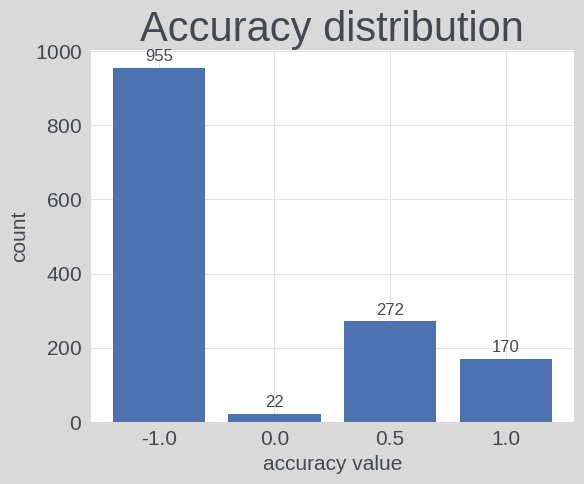

In [6]:
analyze_accuracy("/home/jeonghkim/projects/region-mm-retrieve/results/cragmm/predictions_cragmm_llama-4-scout-17b-16e-instruct_gpt-4o_crop_bbox_gold.jsonl")

HEY!
Average accuracy over 1938 records: -0.5851
Counts: {-1.0: 1444, 0.5: 250, 1.0: 185, 0.0: 59}


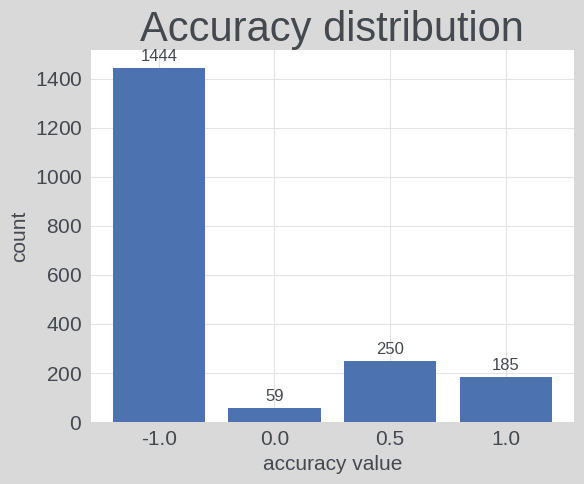

In [8]:
analyze_accuracy("/home/jeonghkim/projects/region-mm-retrieve/results/cragmm/predictions_cragmm_llama-4-scout-17b-16e-instruct_gpt-4o_text_only_retrieved_k_5.jsonl")